# Image classification: from logistic regression to a convolutional network (Fashion-MNIST)
**Data.** Fashion-MNIST (Zalando Research): 70,000 grey-scale 28×28 images of 10 clothing categories, split 60,000 / 10,000. It is a harder drop-in replacement for handwritten digits, where simple models already score about 98%.

**What this shows.** The same task is solved with increasingly expressive models (multinomial logistic regression, a dense neural network, a small CNN), and each is judged on the untouched test set. Then the analysis looks at what the best model still gets wrong, and whether its confidence can be trusted for automatic decisions.

Data is downloaded by `fetch_data.py` (not stored in the repo).

I0000 00:00:1794518639.277871     333 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794518640.141019     333 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


(60000, 28, 28) (10000, 28, 28) | class counts: [6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000]


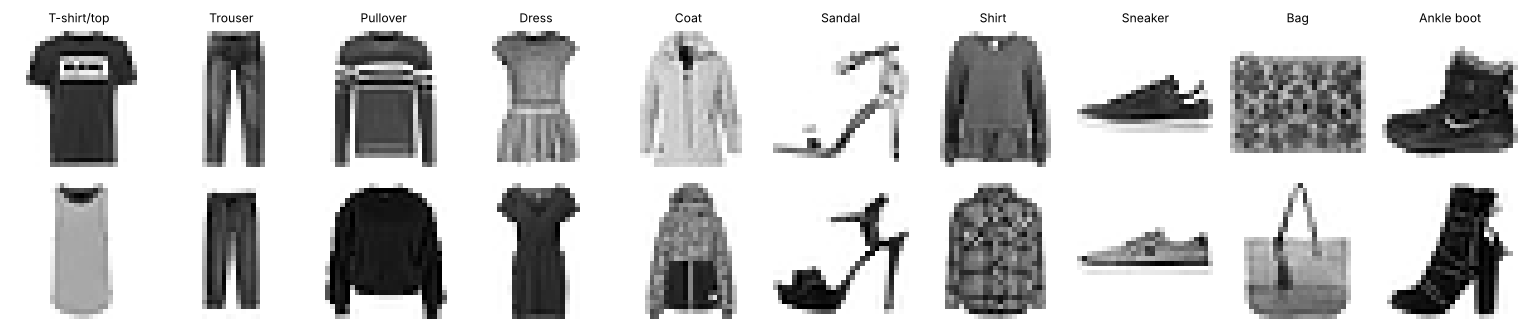

In [1]:
import warnings, pathlib, os
warnings.filterwarnings("ignore"); os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
import time, tensorflow as tf
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
import fetch_data
tf.random.set_seed(0); np.random.seed(0)
xtr, ytr, xte, yte = fetch_data.load()
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
xtr_f, xte_f = xtr / 255.0, xte / 255.0
print(xtr.shape, xte.shape, "| class counts:", np.bincount(ytr).tolist())
fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for c in range(10):
    for r in range(2):
        axes[r, c].imshow(xtr[np.where(ytr == c)[0][r]], cmap="gray_r"); axes[r, c].axis("off")
    axes[0, c].set_title(CLASSES[c], fontsize=8)
plt.tight_layout(); plt.savefig(IMG / "samples.png", bbox_inches="tight"); plt.show()

In [2]:
results = {}
t0 = time.perf_counter()
lr = LogisticRegression(max_iter=200, C=0.1, solver="lbfgs").fit(xtr_f.reshape(len(xtr), -1), ytr)
results["logistic regression"] = {"test accuracy": accuracy_score(yte, lr.predict(xte_f.reshape(len(xte), -1))), "parameters": lr.coef_.size + lr.intercept_.size, "train seconds": time.perf_counter() - t0}
def fit_keras(model, x, name, epochs):
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    t0 = time.perf_counter()
    h = model.fit(x, ytr, validation_split=0.1, epochs=epochs, batch_size=128, verbose=0)
    acc = model.evaluate(xte_f[..., None] if x.ndim == 4 else xte_f, yte, verbose=0)[1]
    results[name] = {"test accuracy": acc, "parameters": model.count_params(), "train seconds": time.perf_counter() - t0}
    return h
mlp = tf.keras.Sequential([tf.keras.layers.Input((28, 28)), tf.keras.layers.Flatten(), tf.keras.layers.Dense(256, activation="relu"),
                           tf.keras.layers.Dropout(0.3), tf.keras.layers.Dense(128, activation="relu"), tf.keras.layers.Dense(10, activation="softmax")])
h_mlp = fit_keras(mlp, xtr_f, "dense network (2 hidden layers)", 15)
cnn = tf.keras.Sequential([tf.keras.layers.Input((28, 28, 1)),
    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"), tf.keras.layers.BatchNormalization(), tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"), tf.keras.layers.BatchNormalization(), tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(), tf.keras.layers.Dropout(0.4), tf.keras.layers.Dense(128, activation="relu"), tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(10, activation="softmax")])
h_cnn = fit_keras(cnn, xtr_f[..., None], "convolutional network (2 conv blocks)", 12)
pd.DataFrame(results).T.round(3)

,test accuracy,parameters,train seconds
logistic regression,0.845,7850.0,35.412
dense network (2 hidden layers),0.888,235146.0,28.315
convolutional network (2 conv blocks),0.911,422026.0,415.503


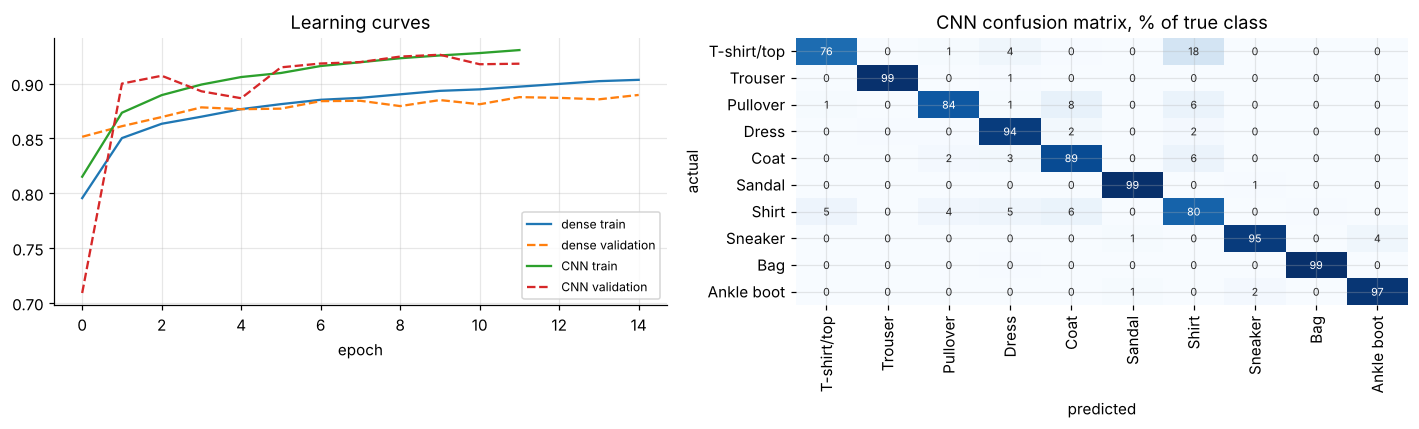

,CNN recall %
T-shirt/top,76.1
Shirt,79.8
Pullover,83.7
Coat,89.0
Dress,94.3
Sneaker,94.8
Ankle boot,96.6
Trouser,98.6
Bag,99.0
Sandal,99.2


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for h, n in [(h_mlp, "dense"), (h_cnn, "CNN")]:
    axes[0].plot(h.history["accuracy"], label=f"{n} train"); axes[0].plot(h.history["val_accuracy"], "--", label=f"{n} validation")
axes[0].set_xlabel("epoch"); axes[0].set_title("Learning curves"); axes[0].legend(fontsize=8)
p = cnn.predict(xte_f[..., None], verbose=0); pred = p.argmax(1)
cm = confusion_matrix(yte, pred); cmn = 100 * cm / cm.sum(1, keepdims=True)
sns.heatmap(pd.DataFrame(cmn, index=CLASSES, columns=CLASSES), annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=axes[1], annot_kws={"fontsize": 7})
axes[1].set_title("CNN confusion matrix, % of true class"); axes[1].set_xlabel("predicted"); axes[1].set_ylabel("actual")
plt.tight_layout(); plt.savefig(IMG / "learning_confusion.png", bbox_inches="tight"); plt.show()
per_class = pd.Series(np.diag(cmn), index=CLASSES).sort_values(); per_class.round(1).to_frame("CNN recall %")

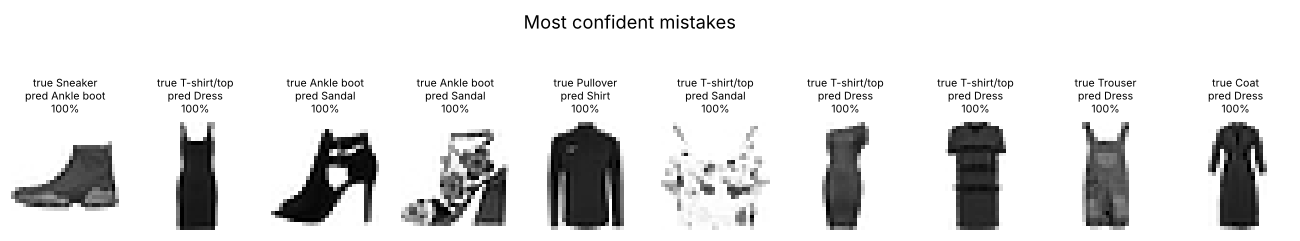

In [4]:
wrong = np.where(pred != yte)[0]; conf = p.max(1)
top_wrong = wrong[np.argsort(-conf[wrong])][:10]
fig, axes = plt.subplots(1, 10, figsize=(15, 2.4))
for ax, i in zip(axes, top_wrong):
    ax.imshow(xte[i], cmap="gray_r"); ax.axis("off"); ax.set_title(f"true {CLASSES[yte[i]]}\npred {CLASSES[pred[i]]}\n{conf[i]:.0%}", fontsize=7)
plt.suptitle("Most confident mistakes", y=1.12); plt.savefig(IMG / "confident_mistakes.png", bbox_inches="tight"); plt.show()

## Can the model's confidence drive automation?
If confident predictions are accepted automatically and the rest go to a person, how much can be automated at a given accuracy? This requires the confidence to be **calibrated**: when the model says 90%, it should be right about 90% of the time.

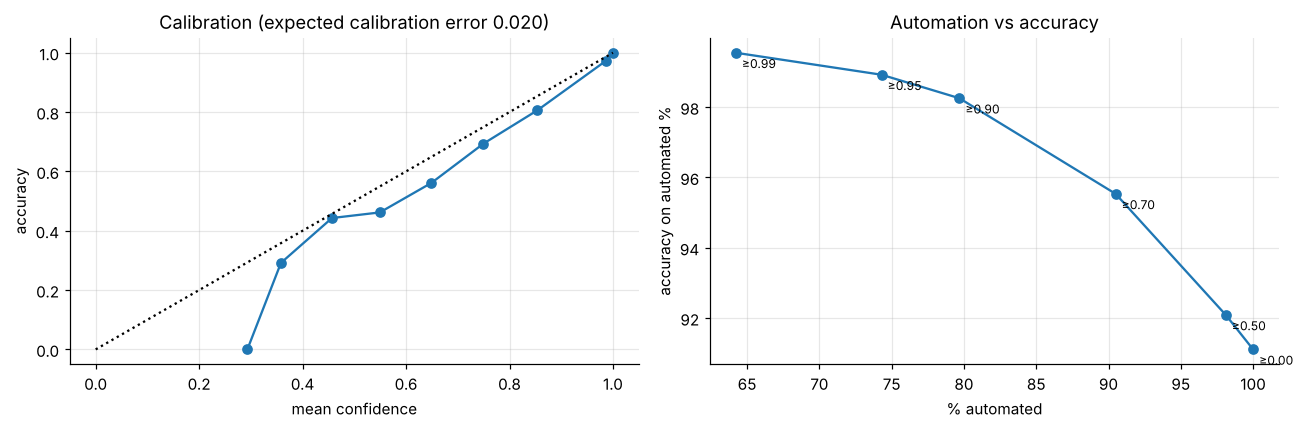

,threshold,automated %,accuracy on automated %
0,0.0,100.0,91.1
1,0.5,98.1,92.1
2,0.7,90.5,95.5
3,0.9,79.7,98.3
4,0.95,74.3,98.9
5,0.99,64.2,99.5


In [5]:
bins = np.linspace(0, 1, 11); idx = np.digitize(conf, bins) - 1
cal = pd.DataFrame({"conf": conf, "correct": pred == yte, "bin": idx}).groupby("bin").agg(mean_conf=("conf", "mean"), accuracy=("correct", "mean"), n=("conf", "size"))
ece = (cal.n * (cal.mean_conf - cal.accuracy).abs()).sum() / cal.n.sum()
rows = [{"threshold": t, "automated %": 100 * (conf >= t).mean(), "accuracy on automated %": 100 * (pred == yte)[conf >= t].mean()} for t in [0, .5, .7, .9, .95, .99]]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(cal.mean_conf, cal.accuracy, "o-"); axes[0].plot([0, 1], [0, 1], "k:"); axes[0].set_xlabel("mean confidence"); axes[0].set_ylabel("accuracy")
axes[0].set_title(f"Calibration (expected calibration error {ece:.3f})")
r = pd.DataFrame(rows); axes[1].plot(r["automated %"], r["accuracy on automated %"], "o-")
for _, x in r.iterrows(): axes[1].annotate(f"≥{x.threshold:.2f}", (x["automated %"], x["accuracy on automated %"]), fontsize=8, xytext=(4, -10), textcoords="offset points")
axes[1].set_xlabel("% automated"); axes[1].set_ylabel("accuracy on automated %"); axes[1].set_title("Automation vs accuracy")
plt.tight_layout(); plt.savefig(IMG / "calibration_automation.png", bbox_inches="tight"); plt.show()
r.round({"threshold": 2, "automated %": 1, "accuracy on automated %": 1})

## Findings
* **Convolutions earn their cost, but less than you might expect.** On the 10,000 held-out images, accuracy rises from 84.5% (logistic regression, 7.9k parameters) to 88.8% (dense network) and 91.1% (CNN, 422k parameters). The CNN took about 7 minutes on 2 CPU cores, against about 30 seconds for the others. A simple linear model is a strong, cheap baseline.
* **Errors concentrate in look-alike classes.** Shirt (80% recall) and T-shirt/top (76%) are the weak classes: 18% of T-shirts are called shirts. Bags, sandals and trousers are recognised 99% of the time. Better accuracy would come from more detail on the top-wear classes, not from more data on the classes it already handles.
* **Some "confident mistakes" are label problems.** Several of the ten most confident errors look like the model is right and the label is not (a "trouser" that is an overall dress). Reviewing high-confidence disagreements is a cheap way to clean training data.
* **Confidence is usable for automation.** The CNN is well calibrated (expected calibration error 0.020). Auto-accepting predictions with confidence ≥ 0.90 handles 80% of images at 98.3% accuracy. At ≥ 0.99 it handles 64% at 99.5%. The rest go to a person. This trade-off is how a document- or image-classification model would be run in an operations or audit setting.